In [1]:
import sys
sys.path.append(r'/Users/kostastsampourakis/Desktop/code/Python/projects/gaussfiltax')

import time

from jax import numpy as jnp
from jax import random as jr
from jax import lax, vmap, pmap, jacfwd, jacrev, debug, device_put, jit
from tensorflow_probability.substrates.jax.distributions import MultivariateNormalFullCovariance as MVN
from typing import List, Optional, NamedTuple, Union
from jaxtyping import Array, Float, Int

# import tensorflow as tf
# tf.test.gpu_device_name()

import gaussfiltax.utils as utils
import gaussfiltax.inference as gf
from gaussfiltax.inference import ParamsUKF, _ukf_predict_nonadditive, PosteriorGaussianSumFiltered, _process_input, _get_params, swap_axes_on_values
from gaussfiltax.models import ParamsNLSSM, NonlinearSSM, ParamsBPF


import matplotlib.pyplot as plt
import matplotlib_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

In [2]:
# # Parameters
# state_dim = 1
# state_noise_dim = 1
# emission_dim = 1
# emission_noise_dim = 1
# seq_length = 100
# mu0 = 0.0 * jnp.zeros(state_dim)
# q0 = jnp.zeros(state_noise_dim)
# r0 = jnp.zeros(emission_noise_dim)
# Sigma0 = 1.0 * jnp.eye(state_dim)
# Q = 1.0 * jnp.eye(state_noise_dim)
# R = 1.0 * jnp.eye(emission_noise_dim)

# # ICASSP
# # f1 = lambda x, q, u: (1-u) * x / 2.  + u * jnp.sin(10 * x) + q
# f1 = lambda x, q, u: 20 * jnp.sin(10 * x) + q
# g1 = lambda x, r, u:  0.01 * jnp.dot(x, x) + r
# def g1lp(x,y,u):
#     return MVN(loc = g1(x, r0, u), covariance_matrix = R).log_prob(y)


# # Lorenz 63
# def lorentz_63(x, sigma=10, rho=28, beta=2.667, dt=0.01):
#     dx = dt * sigma * (x[1] - x[0])
#     dy = dt * (x[0] * rho - x[1] - x[0] *x[2]) 
#     dz = dt * (x[0] * x[1] - beta * x[2])
#     return jnp.array([dx+x[0], dy+x[1], dz+x[2]])
# f63 = lambda x, q, u: lorentz_63(x) + q

# # stochastic growth model
# f3 = lambda x, q, u: x / 2. + 25. * x / (1 + jnp.power(x, 2)) + q
# g3 = lambda x, r, u: u * 0.8 * x + (1-u) * jnp.dot(x, x) + r 
# def g3lp(x,y,u):
#     return MVN(loc = g3(x, 0.0, u), covariance_matrix = R).log_prob(y)


# # Stochastic Volatility
# alpha = 0.91
# sigma = 1.0
# beta = 0.5
# fsv= lambda x, q, u: alpha * x + sigma * q
# gsv = lambda x, r, u: beta * jnp.exp(x/2) * r
# def svlp(x,y,u):
#     return MVN(loc = gsv(x, r0, u), covariance_matrix = gsv(x, 1.0, u)**2 * R).log_prob(y)

# # Linear - Stochastic Volatility
# alpha = 0.91
# sigma = 5.0
# beta = 0.5
# glsv = lambda x, r, u: u * beta * jnp.exp(x/2) * r + (1-u) * (0.8 * x + r)
# def lsvlp(x,y,u):
#     return MVN(loc = glsv(x, r0, u), covariance_matrix = u * beta ** 2 * jnp.exp(x) * R + (1-u) * R).log_prob(y)

# # Multivariate SV
# Phi = 0.8 * jnp.eye(state_dim)
# fmsv = lambda x, q, u: Phi @ x + q #((1-u) + 0.3*u)*q
# gmsv = lambda x, r, u:  u * 0.5 * jnp.multiply(jnp.exp(x/2), r)
# def msvlp(x,y,u):
#     return MVN(loc = gmsv(x, r0, u), covariance_matrix = jnp.diag(jnp.exp(x/2.0)) @ R @ jnp.diag(jnp.exp(x/2.0))).log_prob(y)

# # Linear - Multivariate SV
# sigma = 5.0
# beta = 0.5

# H = 0.1 * jnp.eye(emission_dim, state_dim)
# glmsv = lambda x, r, u: H @ x + r
# # lambda x, r, u: 0 * beta * jnp.multiply(jnp.exp(x / sigma), r) + (1-0) * (H @ x + r)
# def lmsvlp(x,y,u):
#     # M = 0 * beta * jnp.diag(jnp.exp(x / sigma)) + (1-0) * jnp.eye(emission_dim)
#     M = jnp.eye(emission_dim)
#     return MVN(loc = glmsv(x, r0, u), covariance_matrix = M @ R @ M.T).log_prob(y)


# # Linear-Gaussian SSM
# A = 0.8 * jnp.eye(state_dim)
# H = 0.1 * jnp.eye(emission_dim, state_dim)
# fLG = lambda x, q, u: A @ x + q
# gLG = lambda x, r, u: H @ x + r
# gLGlp = lambda x,y,u: MVN(loc = gLG(x, 0.0, u), covariance_matrix = R).log_prob(y)

# # Inputs
# # inputs = 8. * jnp.cos(1.2 * jnp.arange(seq_length))
# # sm = lambda x : jnp.exp(x) / (1+jnp.exp(x))
# # inputs = sm(jnp.arange(seq_length)-50) # off - on gradually
# # inputs = jnp.array([0]*int(seq_length/2) + [1]*int(seq_length/2)) # off - on
# # inputs = 1.0 * jnp.zeros(seq_length) # off
# inputs = vmap(lambda x: jnp.sin(0.1 * x)**2)(jnp.arange(seq_length)) # sine
# # inputs = 1.0 * jnp.ones(seq_length) # on

# f = f3
# g = g3
# glp = g3lp


In [3]:
# # Parameters
# state_dim = 4
# state_noise_dim = 2
# emission_dim = 2
# emission_noise_dim = 2
# seq_length = 500
# mu0 = 1.0 * jnp.array([-0.05, 0.001, 0.7, -0.05])
# q0 = jnp.zeros(state_noise_dim)
# r0 = jnp.zeros(emission_noise_dim)
# Sigma0 = 1.0 * jnp.array([[0.1, 0.0, 0.0, 0.0],[0.0, 0.005, 0.0, 0.0],[0.0, 0.0, 0.1, 0.0],[0.0, 0.0, 0.0, 0.01]])
# Q = 1e-5 * jnp.eye(state_noise_dim)
# R = 25*1e-6 * jnp.eye(emission_noise_dim)

# dt = 0.5
# FCV = 1.0 * jnp.array([[1, dt, 0, 0],[0, 1, 0, 0],[0, 0, 1, dt],[0, 0, 0, 1]])
# acc = 0.5
# Omega = lambda x, acc: 0.1 * acc / jnp.sqrt(x[1]**2 + x[3]**2)
# FCT =  lambda x, a: jnp.array([[1, jnp.sin(dt * Omega(x, a)) / Omega(x, a), 0, -(1-jnp.cos(dt * Omega(x, a))) / Omega(x, a)],
#                             [0, jnp.cos(dt * Omega(x, a)), 0, -jnp.sin(dt * Omega(x, a))],
#                             [0, (1-jnp.cos(dt * Omega(x, a))) / Omega(x, a), 1, jnp.sin(dt * Omega(x, a)) / Omega(x, a)],
#                             [0, jnp.sin(dt * Omega(x, a)), 0, jnp.cos(dt * Omega(x, a))]])

# G = jnp.array([[0.5, 0],[1, 0],[0, 0.5],[0, 1]])
# fBOT = lambda x, q, u: FCV @ x + G @ q
# fManBOT = lambda x, q, u: (0.5*(u-1)*(u-2)*FCV - u*(u-2)*FCT(x, acc) + 0.5*u*(u-1) * FCT(x, -acc)) @ x + G @ q
# gBOT = lambda x, r, u: jnp.arctan2(x[2], x[0]) + r
# gBOT2 = lambda x ,r, u: jnp.array([jnp.arctan2(x[2], x[0]), jnp.sqrt(x[0]**2 + x[2]**2)]) + r
# gBOTlp = lambda x, y, u: MVN(loc = gBOT2(x, r0, u), covariance_matrix = R).log_prob(y)
# # inputs = jnp.zeros((seq_length, 1))
# inputs = jnp.array([1]*int(2*seq_length/5) + [0]*int(seq_length/5) + [2]*int(2*seq_length/5)) # changepoint inputs
# # inputs = vmap(lambda x: 2 * jnp.sin(0.1 * x)**2)(jnp.arange(seq_length)) # sine
# # inputs = jr.choice(jr.PRNGKey(0), jnp.array([0, 1, 2]), shape = (seq_length, 1)) # random inputs

# f = fManBOT
# g = gBOT2
# glp = gBOTlp

In [4]:
# Parameters
state_dim = 10
state_noise_dim = 10
emission_dim = 10
emission_noise_dim = 10
seq_length = 200
mu0 = 0.0 * jnp.zeros(state_dim)
q0 = jnp.zeros(state_noise_dim)
r0 = 0.0001 * jnp.ones(emission_noise_dim)
Sigma0 = 1.0 * jnp.eye(state_dim)
Q = 10.0 * jnp.eye(state_noise_dim)
R = 0.1 * jnp.eye(emission_noise_dim)

# Model functions
Phi = 0.8 * jnp.eye(state_dim)
fmsv = lambda x, q, u: Phi @ x + q #((1-u) + 0.3*u)*q

sigma = 5.0
beta = 0.5
H0 = jnp.eye(emission_dim, state_dim)
glmsv = lambda x, r, u: u * beta * jnp.multiply(jnp.exp(x / sigma), r) + (1-u) * (H0 @ x + r)
def lmsvlp(x,y,u):
    M = u * beta * jnp.diag(jnp.exp(x / sigma)) + (1-u) * jnp.eye(emission_dim)
    return MVN(loc = glmsv(x, r0, u), covariance_matrix = M @ R @ M.T).log_prob(y)

# Inputs
# inputs = jnp.array([0]*int(seq_length/2) + [1]*int(seq_length/2)) # off - on
inputs = vmap(lambda x: jnp.sin(0.1 * x)**2)(jnp.arange(seq_length)) # sine
# inputs = jr.uniform(jr.PRNGKey(0), (seq_length,))
# inputs = jnp.zeros(seq_length) # off
# inputs = jnp.ones(seq_length) # on
# plt.plot(inputs)
# plt.show()

f = fmsv
g = glmsv
glp = lmsvlp

In [5]:
# initialization
model = NonlinearSSM(state_dim, state_noise_dim, emission_dim, emission_noise_dim)
params = ParamsNLSSM(
    initial_mean=mu0,
    initial_covariance=Sigma0,
    dynamics_function=f,
    dynamics_noise_bias= q0,
    dynamics_noise_covariance=Q,
    emission_function=g,
    emission_noise_bias= r0,
    emission_noise_covariance=R,
)

In [6]:
def rmse(x_est, x_base):
    T = x_est.shape[0]
    sum_sq = jnp.sum((x_est - x_base) ** 2)
    return jnp.sqrt(sum_sq / T)

sim 1/5
key0:  [2467461003  428148500]
key:  [3186719485 3840466878]
       Time taken for GSF:  0.6458840370178223
       Time taken for UGSF:  1.91432785987854
       Time taken for AGSF:  17.714919090270996
       Time taken for UAGSF:  47.149534940719604
       Time taken for BPF:  0.8605928421020508


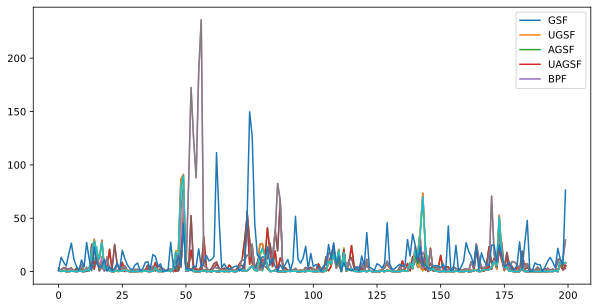

sim 2/5
key0:  [4038682467 4049047219]
key:  [1123993949 1633776119]
       Time taken for GSF:  0.6219208240509033
       Time taken for UGSF:  1.8661670684814453
       Time taken for AGSF:  16.03765320777893
       Time taken for UAGSF:  46.7194459438324
       Time taken for BPF:  0.8700957298278809


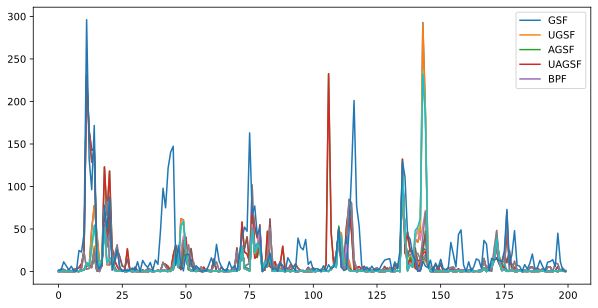

sim 3/5
key0:  [3295730785 1907469606]
key:  [2175656443 3507338041]
       Time taken for GSF:  0.632066011428833
       Time taken for UGSF:  1.9019393920898438
       Time taken for AGSF:  16.786738872528076
       Time taken for UAGSF:  47.20833611488342
       Time taken for BPF:  0.8735780715942383


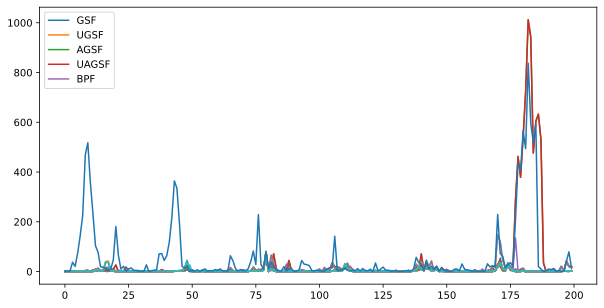

sim 4/5
key0:  [1795368326  584935165]
key:  [1120832370 3770592918]
       Time taken for GSF:  0.630856990814209
       Time taken for UGSF:  1.890838861465454
       Time taken for AGSF:  16.998673915863037
       Time taken for UAGSF:  47.425143241882324
       Time taken for BPF:  0.8885009288787842


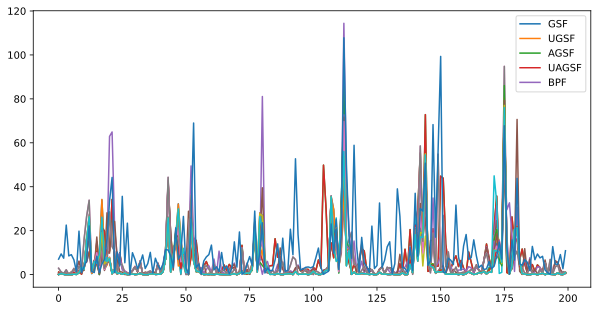

sim 5/5
key0:  [ 456292018 1165566599]
key:  [4102745572 3277364256]
       Time taken for GSF:  0.6360080242156982
       Time taken for UGSF:  1.8936340808868408
       Time taken for AGSF:  16.803428888320923
       Time taken for UAGSF:  48.321091651916504
       Time taken for BPF:  0.87845778465271


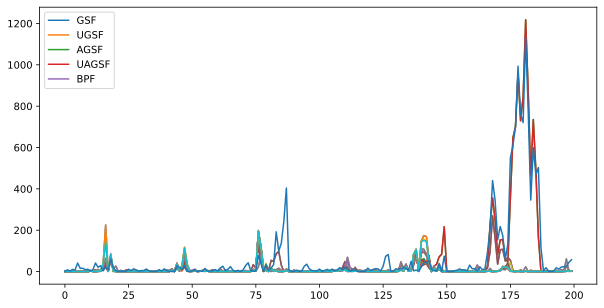

In [18]:
verbose = False
Nsim = 5
# rho1, rho2 = jnp.meshgrid(0.99 * jnp.arange(1, 2), 0.1 * jnp.arange(1, 10))
rho1, rho2 = jnp.meshgrid(jnp.array([0.01, 0.5, 0.99]), jnp.array([0.01, 0.5, 0.99]))
opt_arg_pairs = jnp.array([rho1.ravel(), rho2.ravel()]).T

gsf_rmse = jnp.zeros(Nsim)
ugsf_rmse = jnp.zeros(Nsim)
agsf_rmse = jnp.zeros((Nsim, len(opt_arg_pairs)))
uagsf_rmse = jnp.zeros((Nsim, len(opt_arg_pairs)))
bpf_rmse = jnp.zeros(Nsim)

gsf_norm = jnp.zeros((Nsim, seq_length))
ugsf_norm = jnp.zeros((Nsim, seq_length))
agsf_norm = jnp.zeros((Nsim, seq_length, len(opt_arg_pairs)))
uagsf_norm = jnp.zeros((Nsim, seq_length, len(opt_arg_pairs)))
bpf_norm = jnp.zeros((Nsim, seq_length))

gsf_time = jnp.zeros(Nsim)
ugsf_time = jnp.zeros(Nsim)
agsf_time = jnp.zeros(Nsim)
uagsf_time = jnp.zeros(Nsim)
bpf_time = jnp.zeros(Nsim)
gspf_time = jnp.zeros(Nsim)
next_key = jr.PRNGKey(0)


for i in range(Nsim):
    print('sim {}/{}'.format(i+1, Nsim))
    # Generate Data
    key0, key, next_key = jr.split(next_key, 3)
    print('key0: ', key0)
    print('key: ', key)
    states, emissions = model.sample(params, key0, seq_length, inputs = inputs)

    # GSF
    M = 100
    tin = time.time()
    posterior_filtered_gsf = gf.gaussian_sum_filter(params, emissions, M, 1, inputs)
    point_estimate_gsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_gsf.means, posterior_filtered_gsf.weights), axis=0)
    tout = time.time()
    t_gsf= tout - tin
    print('       Time taken for GSF: ', tout - tin)

    # U-GSF
    tin = time.time()
    uparams = ParamsUKF(1,0,0)
    posterior_filtered_ugsf = gf.unscented_gaussian_sum_filter(params, uparams, emissions, M, 1, inputs)
    point_estimate_ugsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_ugsf.means, posterior_filtered_ugsf.weights), axis=0)
    tout = time.time()
    t_ugsf= tout - tin
    print('       Time taken for UGSF: ', tout - tin)

    # AGSF
    tin = time.time()
    num_components = [100, 5, 5]
    posterior_filtered_agsf, aux_outputs = vmap(gf.speedy_augmented_gaussian_sum_filter, in_axes=(None, None, None, None, None, 0, None))(params, emissions, num_components, key, 1, opt_arg_pairs, inputs)    
    point_estimates_agsf = vmap(lambda posterior_filtered: jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered.means, posterior_filtered.weights), axis=0))(posterior_filtered_agsf)
    tout = time.time()
    t_agsf= tout - tin
    print('       Time taken for AGSF: ', tout - tin)

    # U-AGSF
    tin = time.time()
    posterior_filtered_uagsf, aux_outputs = vmap(gf.speedy_unscented_agsf, in_axes=(None, None, None, None, None, 0, None))(params, uparams, emissions, num_components, key, opt_arg_pairs, inputs)
    point_estimates_uagsf = vmap(lambda posterior_filtered: jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered.means, posterior_filtered.weights), axis=0))(posterior_filtered_uagsf)
    tout = time.time()
    t_uagsf = tout - tin
    print('       Time taken for UAGSF: ', tout - tin)

    # BPF
    tin = time.time()
    num_particles = 1000

    params_bpf = ParamsBPF(
        initial_mean=mu0,
        initial_covariance=Sigma0,
        dynamics_function=f,
        dynamics_noise_bias=q0,
        dynamics_noise_covariance=Q,
        emission_function=g,
        emission_noise_bias=r0,
        emission_noise_covariance=R,
        emission_distribution_log_prob = glp
    )

    posterior_bpf = gf.bootstrap_particle_filter(params_bpf, emissions, num_particles, key, inputs, 1.0)
    point_estimate_bpf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_bpf["particles"], posterior_bpf["weights"]), axis=0)
    tout = time.time()
    t_bpf = tout - tin
    print('       Time taken for BPF: ', tout - tin)


    # Computation of errors
    d=state_dim
    gsf_rmse = gsf_rmse.at[i].set(rmse(point_estimate_gsf[:, (0,d)], states[:, (0,d)]))
    ugsf_rmse = ugsf_rmse.at[i].set(rmse(point_estimate_ugsf[:, (0,d)], states[:, (0,d)]))
    agsf_rmse = agsf_rmse.at[i].set(vmap(lambda point_estimate: rmse(point_estimate[:, (0,d)], states[:, (0,d)]))(point_estimates_agsf))
    uagsf_rmse = uagsf_rmse.at[i].set(vmap(lambda point_estimate: rmse(point_estimate[:, (0,d)], states[:, (0,d)]))(point_estimates_uagsf))
    bpf_rmse = bpf_rmse.at[i].set(rmse(point_estimate_bpf[:, (0,d)], states[:, (0,d)]))

    gsf_norm = gsf_norm.at[i].set(jnp.linalg.norm(point_estimate_gsf[:,(0,d)] - states[:,(0,d)], axis = 1)**2)
    ugsf_norm = ugsf_norm.at[i].set(jnp.linalg.norm(point_estimate_ugsf[:,(0,d)] - states[:,(0,d)], axis = 1)**2)
    agsf_norm = agsf_norm.at[i].set(vmap(lambda point_estimate: jnp.linalg.norm(point_estimate[:,(0,d)] - states[:,(0,d)], axis = 1)**2)(point_estimates_agsf).T)
    uagsf_norm = uagsf_norm.at[i].set(vmap(lambda point_estimate: jnp.linalg.norm(point_estimate[:,(0,d)] - states[:,(0,d)], axis = 1)**2)(point_estimates_uagsf).T)
    bpf_norm = bpf_norm.at[i].set(jnp.linalg.norm(point_estimate_bpf[:,(0,d)] - states[:,(0,d)], axis = 1)**2)

    fig, axes = plt.subplots(1, 1, figsize=(10, 5))

    axes.plot(gsf_norm[i])
    axes.plot(ugsf_norm[i])
    for j in range(len(opt_arg_pairs)):
        axes.plot(agsf_norm[i, :, j])
        axes.plot(uagsf_norm[i, :, j])
    axes.plot(bpf_norm[i])
    axes.legend(['GSF', 'UGSF', 'AGSF', 'UAGSF', 'BPF'])

    plt.show()


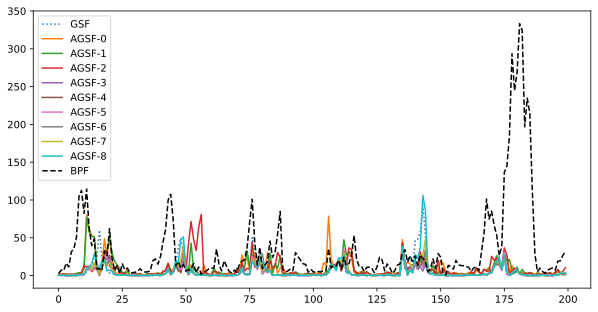

In [10]:
# ind1 = jnp.unique(jnp.argwhere(jnp.isnan(gsf_norm)).T[0])
# ind2 = jnp.unique(jnp.argwhere(gsf_norm > 5000).T[0])
# ind = jnp.unique(jnp.concatenate((ind1, ind2)))
# gsf_avg_norm = jnp.mean(jnp.delete(gsf_norm, ind, axis = 0), axis = 0)

# ind3 = jnp.unique(jnp.argwhere(agsf_norm > 1000).T[0])
# agsf_avg_norm = jnp.mean(jnp.delete(agsf_norm, ind3, axis = 0), axis = 0)

# bpf_avg_norm = jnp.mean(bpf_norm, axis = 0)

# fig, axes = plt.subplots(1, 1, figsize=(10, 5))

# axes.plot(gsf_avg_norm, label = 'GSF', linestyle = ':')
# # axes.plot(ugsf_avg_norm, label = 'UGSF')
# for i in range(len(opt_arg_pairs)):
#     axes.plot(agsf_avg_norm[:, i], label = 'AGSF-{}'.format(i))
#     # axes.plot(uagsf_avg_norm[:, i], label = 'UAGSF-{}'.format(i))
# axes.plot(bpf_avg_norm, label = 'BPF', linestyle = '--', color = 'black')
# axes.legend()

# plt.show()


In [22]:
gsf_armse = jnp.mean(gsf_rmse)
ugsf_armse = jnp.mean(ugsf_rmse)
agsf_armse = jnp.mean(agsf_rmse, axis = 0)
uagsf_armse = jnp.mean(uagsf_rmse, axis = 0)
bpf_armse = jnp.mean(bpf_rmse)

Array([4.5661025, 2.9858875, 2.8675315, 1.9940857, 1.9850895, 1.968687 ,
       2.067087 , 2.1328895, 2.3459098], dtype=float32)

In [75]:
agsf_rmse.shape

(5, 9)

In [101]:
import pandas as pd

# Remove NaNs and compute success percentage
ind_gsf = jnp.unique(jnp.argwhere(jnp.isnan(gsf_rmse)))
gsf_rmse = jnp.delete(gsf_rmse, ind_gsf, axis = 0)
gsf_success_pct = int(100 - 100*len(ind_gsf) / Nsim)

ind_ugsf = jnp.unique(jnp.argwhere(jnp.isnan(ugsf_rmse)))
ugsf_rmse = jnp.delete(ugsf_rmse, ind_ugsf, axis = 0)
ugsf_success_pct = int(100 - 100* len(ind_ugsf) / Nsim)

ind_bpf = jnp.unique(jnp.argwhere(jnp.isnan(bpf_rmse)))
bpf_rmse = jnp.delete(bpf_rmse, ind_bpf, axis = 0)
bpf_success_pct = int(100 - 100*len(ind_bpf) / Nsim)


keys = jr.split(jr.PRNGKey(0), 5)
B = 100
gsf_boot = utils.bootstrap(keys[0], gsf_rmse, B)
ugsf_boot = utils.bootstrap(keys[1], ugsf_rmse, B)
bpf_boot = utils.bootstrap(keys[4], bpf_rmse, B)
pct_agsf, armse_agsf, std_agf = utils.vec_clean_and_rmse(agsf_rmse, keys[2], B, Nsim)
pct_uagsf, armse_uagsf, std_uagf = utils.vec_clean_and_rmse(uagsf_rmse, keys[3], B, Nsim)

gsf_armse = jnp.mean(gsf_boot)
ugsf_armse = jnp.mean(ugsf_boot)
bpf_armse = jnp.mean(bpf_boot)

gsf_atime = jnp.mean(gsf_time)
ugsf_atime = jnp.mean(ugsf_time)
agsf_atime = jnp.mean(agsf_time)
uagsf_atime = jnp.mean(uagsf_time)
bpf_atime = jnp.mean(bpf_time)



gsf_tab_out = '{:2.3f}±{:2.2f}({}%)'.format(gsf_armse, jnp.std(gsf_rmse), gsf_success_pct)
ugsf_tab_out = '{:2.3f}±{:2.2f}({}%)'.format(ugsf_armse, jnp.std(ugsf_rmse), ugsf_success_pct)
bpf_tab_out = '{:2.3f}±{:2.2f}({}%)'.format(bpf_armse, jnp.std(bpf_boot), bpf_success_pct)
agsf_tab_out = ['{:2.3f}±{:2.2f}({}%)'.format(armse_agsf[i], std_agf[i], pct_agsf[i]) for i in range(len(armse_agsf))]
uagsf_tab_out = ['{:2.3f}±{:2.2f}({}%)'.format(armse_uagsf[i], std_uagf[i], pct_uagsf[i]) for i in range(len(armse_uagsf))]

# gsf_tab_out1 = '{:2.2f}±{:2.2f}'.format(gsf_atime, jnp.std(gsf_time))
# ugsf_tab_out1 = '{:2.2f}±{:2.2f}'.format(ugsf_atime, jnp.std(ugsf_time))
# agsf_tab_out1 = '{:2.2f}±{:2.2f}'.format(agsf_atime, jnp.std(agsf_time))
# uagsf_tab_out1 = '{:2.2f}±{:2.2f}'.format(uagsf_atime, jnp.std(uagsf_time))
# bpf_tab_out1 = '{:2.2f}±{:2.2f}'.format(bpf_atime, jnp.std(bpf_time))

df = pd.DataFrame(columns = [' ','RMSE'])
# df[' '] = ['GSF', 'AGSF', 'AGSF Optimal', 'BPF']
# df['RMSE'] = [gsf_tab_out, agsf_tab_out, agsf_opt_tab_out, bpf_tab_out]
# df['time(s)'] = [gsf_tab_out1, agsf_tab_out1, agsf_opt_tab_out1, bpf_tab_out1]
df[' '] = ['GSF','UGSF'] + ['AGSF-{}'.format(i) for i in range(len(opt_arg_pairs))] + ['UAGSF-{}'.format(i) for i in range(len(opt_arg_pairs))] + ['BPF']
df['RMSE'] = [gsf_tab_out, ugsf_tab_out] + agsf_tab_out + uagsf_tab_out + [bpf_tab_out]
# df['time(s)'] = [gsf_tab_out1, ugsf_tab_out1, agsf_tab_out1, uagsf_tab_out1, bpf_tab_out1]
print(df.to_latex(index=False))
df


\begin{tabular}{ll}
\toprule
  & RMSE \\
\midrule
GSF & 2.409±0.53(100%) \\
UGSF & 2.438±0.53(100%) \\
AGSF-0 & 4.595±0.81(100%) \\
AGSF-1 & 2.992±0.22(100%) \\
AGSF-2 & 2.874±0.10(100%) \\
AGSF-3 & 1.995±0.17(100%) \\
AGSF-4 & 1.987±0.18(100%) \\
AGSF-5 & 1.971±0.16(100%) \\
AGSF-6 & 2.042±0.20(100%) \\
AGSF-7 & 2.094±0.17(100%) \\
AGSF-8 & 2.371±0.22(100%) \\
UAGSF-0 & 4.371±0.85(100%) \\
UAGSF-1 & 2.915±0.26(100%) \\
UAGSF-2 & 2.859±0.10(100%) \\
UAGSF-3 & 1.964±0.14(100%) \\
UAGSF-4 & 1.962±0.17(100%) \\
UAGSF-5 & 1.992±0.16(100%) \\
UAGSF-6 & 2.081±0.19(100%) \\
UAGSF-7 & 2.089±0.18(100%) \\
UAGSF-8 & 2.357±0.20(100%) \\
BPF & 5.655±0.90(100%) \\
\bottomrule
\end{tabular}



,,RMSE
0,GSF,2.409±0.53(100%)
1,UGSF,2.438±0.53(100%)
2,AGSF-0,4.595±0.81(100%)
3,AGSF-1,2.992±0.22(100%)
4,AGSF-2,2.874±0.10(100%)
5,AGSF-3,1.995±0.17(100%)
6,AGSF-4,1.987±0.18(100%)
7,AGSF-5,1.971±0.16(100%)
8,AGSF-6,2.042±0.20(100%)
9,AGSF-7,2.094±0.17(100%)
